# Biohub – Cell Tracking During Development · EDA

This notebook explores the [competition dataset](https://kaggle.com/competitions/biohub-cell-tracking-during-development).
The task is to **track cells across frames in 3D+time fluorescence microscopy** with sparse ground truth.

### Data format
- **Images**: OME-Zarr `(T=100, Z=64, Y=256, X=256)` uint16, scale `1.625 × 0.406 × 0.406 µm/px`
- **Tracks**: GEFF graphs — nodes are cell centres `(t, z, y, x)`, edges link cells across consecutive frames
- **Divisions**: encoded as one source node with **two outgoing edges**
- Ground truth is **sparse**: only a subset of cells are annotated per video

### Scoring
`score = adjusted_edge_jaccard + 0.1 × division_jaccard`  (micro-averaged TP/FP/FN)

---

In [2]:
import os
import sys
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

import numpy as np
import polars as pl
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.ticker import MaxNLocator
import zarr
import tracksdata as td

sys.path.insert(0, '../src')

TRAIN_DIR = Path('../input/train')
TEST_DIR  = Path('../input/test')

# ── Reference palette (palette.md) ──────────────────────────────────────────
SURFACE    = '#fcfcfb'
TEXT_PRI   = '#0b0b0b'
TEXT_SEC   = '#52514e'
TEXT_MUTED = '#898781'
GRID       = '#e1e0d9'
BASELINE   = '#c3c2b7'

C1 = '#2a78d6'   # slot 1 blue   → 44b6 embryo series
C2 = '#eb6834'   # slot 2 orange → 6bba embryo series
C3 = '#1baf7a'   # slot 3 aqua   → third series in line chart

# Sequential blue steps (light → dark) for box-plot fills
SEQ = ['#cde2fb','#b7d3f6','#9ec5f4','#86b6ef','#6da7ec',
       '#5598e7','#3987e5','#2a78d6','#256abf','#1c5cab']

plt.rcParams.update({
    'figure.facecolor': SURFACE,
    'axes.facecolor':   SURFACE,
    'axes.edgecolor':   BASELINE,
    'axes.linewidth':   0.75,
    'axes.grid':        True,
    'grid.color':       GRID,
    'grid.linewidth':   0.5,
    'text.color':       TEXT_PRI,
    'axes.labelcolor':  TEXT_SEC,
    'xtick.color':      TEXT_MUTED,
    'ytick.color':      TEXT_MUTED,
    'xtick.labelsize':  10,
    'ytick.labelsize':  10,
    'axes.titlesize':   12,
    'axes.titleweight': 'semibold',
    'axes.spines.top':   False,
    'axes.spines.right': False,
    'font.family': 'sans-serif',
    'figure.dpi': 120,
})
print('Setup complete.')

Setup complete.


## 1 · Load dataset metadata

Iterate over all 199 training `.geff` files and extract per-dataset counts.
This takes ~30 seconds (no images are loaded).

In [3]:
geff_files = sorted(TRAIN_DIR.glob('*.geff'))
zarr_files = sorted(TRAIN_DIR.glob('*.zarr'))
test_zarrs = sorted(TEST_DIR.glob('*.zarr'))

SRC = td.DEFAULT_ATTR_KEYS.EDGE_SOURCE

rows = []
for gf in geff_files:
    prefix = gf.stem.split('_')[0]
    result = td.graph.IndexedRXGraph.from_geff(gf)
    g = result[0] if isinstance(result, tuple) else result
    node_df = g.node_attrs()
    edge_df  = g.edge_attrs()
    n_nodes  = g.num_nodes()
    n_edges  = g.num_edges()
    divs = 0
    if n_edges > 0:
        out_deg = edge_df.group_by(SRC).agg(pl.len().alias('od'))
        divs = out_deg.filter(pl.col('od') >= 2).height
    rows.append({
        'name':               gf.stem,
        'prefix':             prefix,
        'nodes':              n_nodes,
        'edges':              n_edges,
        'divisions':          divs,
        'n_frames_annotated': int(node_df['t'].n_unique()),
        't_min':              int(node_df['t'].min()),
        't_max':              int(node_df['t'].max()),
    })

df = pl.DataFrame(rows)
print(f'Train: {len(df)} videos   |   Test: {len(test_zarrs)} videos')
df.head()

Train: 199 videos   |   Test: 4 videos


name,prefix,nodes,edges,divisions,n_frames_annotated,t_min,t_max
str,str,i64,i64,i64,i64,i64,i64
"""44b6_0113de3b""","""44b6""",52,50,0,52,0,75
"""44b6_0b24845f""","""44b6""",51,49,0,40,11,50
"""44b6_0c582fdc""","""44b6""",71,70,0,71,20,90
"""44b6_0db75fae""","""44b6""",157,151,0,89,0,88
"""44b6_12dfb391""","""44b6""",788,773,1,100,0,99


In [3]:
# Collect pre-computed intensity quantiles from zarr attrs (instant — no pixel data loaded)
quant_rows = []
for zf in zarr_files:
    zg  = zarr.open_group(str(zf))
    qs  = dict(zg.attrs).get('image_statistics', {}).get('quantiles', {})
    row = {'name': zf.stem, 'prefix': zf.stem.split('_')[0]}
    for k, v in qs.items():
        row[f'q{k}'] = float(v)
    quant_rows.append(row)

qdf = pl.DataFrame(quant_rows)
print(f'Quantiles loaded for {len(qdf)} training videos')
print(qdf.describe())

Quantiles loaded for 199 training videos
shape: (9, 11)
┌────────────┬────────────┬────────┬───────────┬───┬───────────┬───────────┬───────────┬───────────┐
│ statistic  ┆ name       ┆ prefix ┆ q0.0      ┆ … ┆ q0.9      ┆ q0.99     ┆ q0.999    ┆ q1.0      │
│ ---        ┆ ---        ┆ ---    ┆ ---       ┆   ┆ ---       ┆ ---       ┆ ---       ┆ ---       │
│ str        ┆ str        ┆ str    ┆ f64       ┆   ┆ f64       ┆ f64       ┆ f64       ┆ f64       │
╞════════════╪════════════╪════════╪═══════════╪═══╪═══════════╪═══════════╪═══════════╪═══════════╡
│ count      ┆ 199        ┆ 199    ┆ 199.0     ┆ … ┆ 199.0     ┆ 199.0     ┆ 199.0     ┆ 199.0     │
│ null_count ┆ 0          ┆ 0      ┆ 0.0       ┆ … ┆ 0.0       ┆ 0.0       ┆ 0.0       ┆ 0.0       │
│ mean       ┆ null       ┆ null   ┆ 21.38191  ┆ … ┆ 917.98377 ┆ 1465.8118 ┆ 1993.8550 ┆ 3535.3266 │
│            ┆            ┆        ┆           ┆   ┆ 9         ┆ 67        ┆ 39        ┆ 33        │
│ std        ┆ null       ┆ null   

## 2 · Competition overview

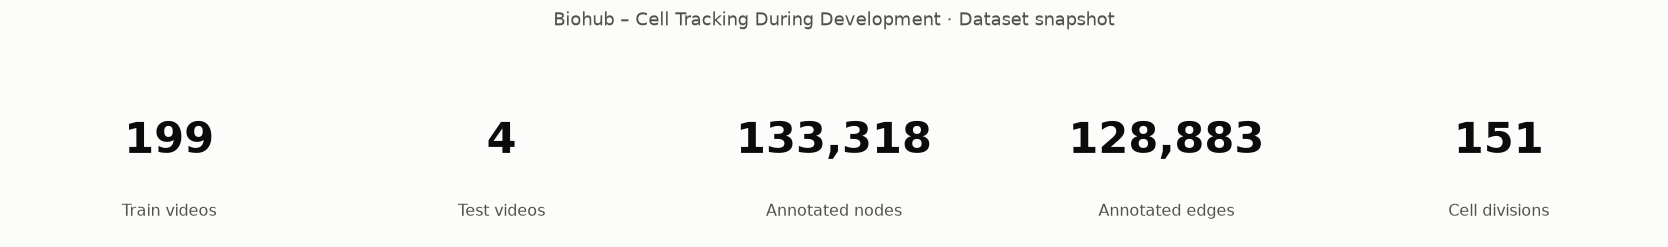

In [4]:
kpis = [
    (str(len(df)),                  'Train videos'),
    (str(len(test_zarrs)),          'Test videos'),
    (f"{df['nodes'].sum():,}",      'Annotated nodes'),
    (f"{df['edges'].sum():,}",      'Annotated edges'),
    (f"{df['divisions'].sum():,}",  'Cell divisions'),
]

fig, axes = plt.subplots(1, 5, figsize=(14, 1.9), facecolor=SURFACE)
for ax, (val, label) in zip(axes, kpis):
    ax.set_facecolor(SURFACE)
    ax.axis('off')
    for sp in ax.spines.values():
        sp.set_visible(True)
        sp.set_color(GRID)
        sp.set_linewidth(0.75)
    ax.text(0.5, 0.60, val,   ha='center', va='center',
            fontsize=26, fontweight='bold', color=TEXT_PRI,
            transform=ax.transAxes)
    ax.text(0.5, 0.15, label, ha='center', va='center',
            fontsize=9.5, color=TEXT_SEC, transform=ax.transAxes)

fig.suptitle('Biohub – Cell Tracking During Development · Dataset snapshot',
             y=1.06, fontsize=11, color=TEXT_SEC)
plt.tight_layout()
plt.show()

## 3 · Embryo series & annotation density

findfont: Failed to find font weight semibold, now using 700.


findfont: Failed to find font weight semibold, now using 700.


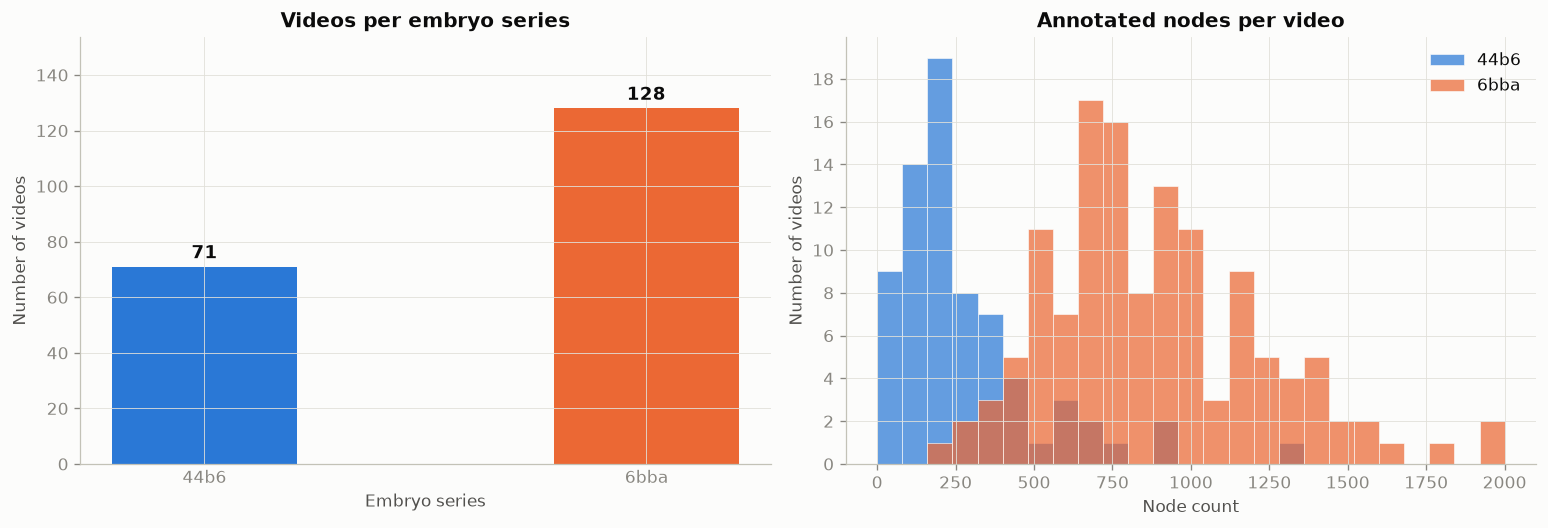

In [5]:
by_prefix = df.group_by('prefix').agg(pl.len().alias('count')).sort('prefix')
prefix_colors = {'44b6': C1, '6bba': C2}

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
fig.patch.set_facecolor(SURFACE)

# ── Left: videos per embryo series ──────────────────────────────────────────
names  = by_prefix['prefix'].to_list()
counts = by_prefix['count'].to_list()
bars = ax1.bar(names, counts,
               color=[prefix_colors[n] for n in names],
               width=0.42, edgecolor=SURFACE, linewidth=0)
for bar, cnt in zip(bars, counts):
    ax1.text(bar.get_x() + bar.get_width() / 2,
             bar.get_height() + 1.5,
             str(cnt), ha='center', va='bottom',
             fontsize=11, fontweight='semibold', color=TEXT_PRI)
ax1.set_title('Videos per embryo series')
ax1.set_xlabel('Embryo series', color=TEXT_SEC)
ax1.set_ylabel('Number of videos', color=TEXT_SEC)
ax1.set_ylim(0, max(counts) * 1.2)
ax1.tick_params(axis='x', length=0)

# ── Right: node-count histogram, split by prefix ────────────────────────────
bins = np.linspace(0, df['nodes'].max() + 50, 26)
for prefix, color in prefix_colors.items():
    vals = df.filter(pl.col('prefix') == prefix)['nodes'].to_numpy()
    ax2.hist(vals, bins=bins, color=color, alpha=0.72,
             edgecolor=SURFACE, linewidth=0.5, label=prefix)
ax2.set_title('Annotated nodes per video')
ax2.set_xlabel('Node count', color=TEXT_SEC)
ax2.set_ylabel('Number of videos', color=TEXT_SEC)
ax2.yaxis.set_major_locator(MaxNLocator(integer=True))
ax2.legend(frameon=False, labelcolor=TEXT_PRI, fontsize=10)

plt.tight_layout()
plt.show()

## 4 · Nodes vs edges — annotation sparsity

In a fully annotated video every edge connects two annotated nodes, so `edges ≈ nodes − T`.
The tighter the scatter hugs the diagonal, the more complete the annotation coverage.

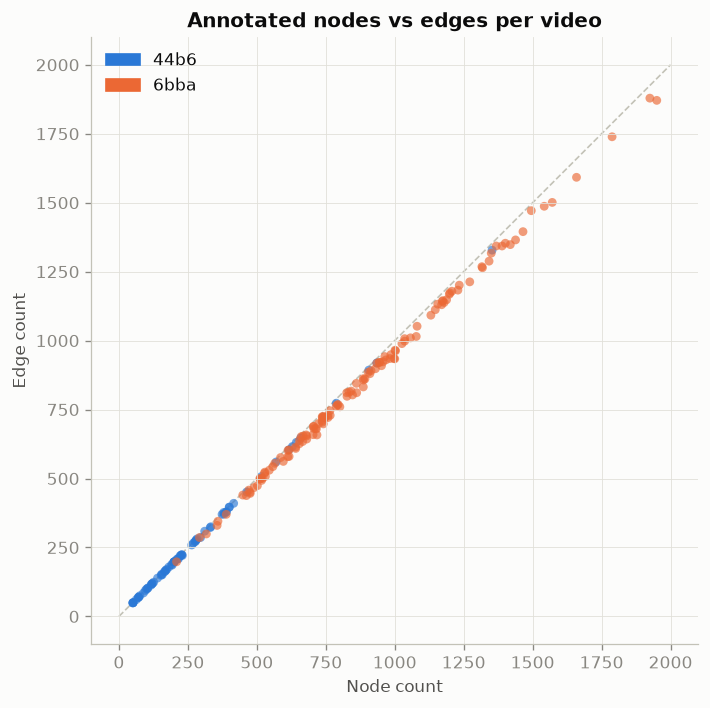

In [6]:
fig, ax = plt.subplots(figsize=(7, 6))
fig.patch.set_facecolor(SURFACE)

for prefix, color in prefix_colors.items():
    sub = df.filter(pl.col('prefix') == prefix)
    ax.scatter(sub['nodes'].to_numpy(), sub['edges'].to_numpy(),
               c=color, s=28, alpha=0.65, edgecolors='none', label=prefix)

# diagonal reference: edges = nodes (perfect one-track-per-frame annotation)
diag_max = int(df['nodes'].max()) + 50
ax.plot([0, diag_max], [0, diag_max], color=BASELINE,
        linewidth=1, linestyle='--', zorder=0, label='edges = nodes')

patch1 = mpatches.Patch(color=C1, label='44b6')
patch2 = mpatches.Patch(color=C2, label='6bba')
ax.legend(handles=[patch1, patch2], frameon=False, labelcolor=TEXT_PRI, fontsize=10)

ax.set_title('Annotated nodes vs edges per video')
ax.set_xlabel('Node count', color=TEXT_SEC)
ax.set_ylabel('Edge count', color=TEXT_SEC)
ax.set_aspect('equal', adjustable='box')
plt.tight_layout()
plt.show()

## 5 · Cell divisions

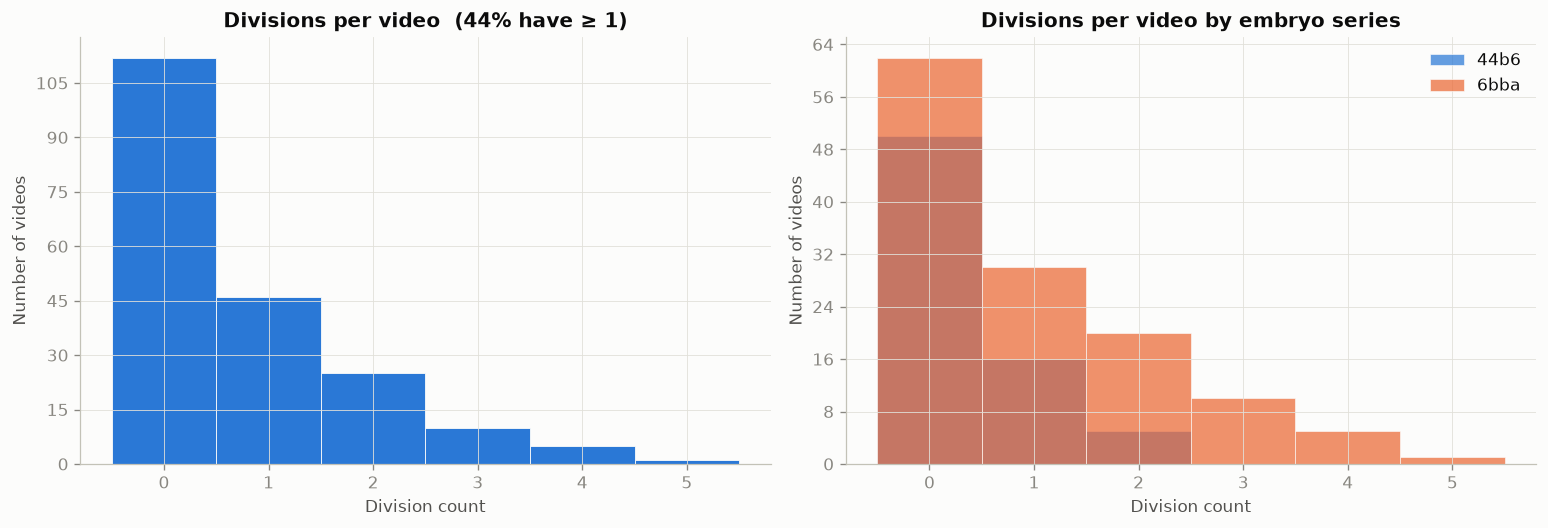

In [7]:
div_counts   = df['divisions'].to_numpy()
pct_with     = 100 * (div_counts > 0).sum() / len(div_counts)
max_div      = int(div_counts.max())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
fig.patch.set_facecolor(SURFACE)

# ── Left: overall distribution ───────────────────────────────────────────────
bins = np.arange(-0.5, max_div + 1.5)
ax1.hist(div_counts, bins=bins, color=C1, edgecolor=SURFACE, linewidth=0.5)
ax1.set_title(f'Divisions per video  ({pct_with:.0f}% have ≥ 1)')
ax1.set_xlabel('Division count', color=TEXT_SEC)
ax1.set_ylabel('Number of videos', color=TEXT_SEC)
ax1.xaxis.set_major_locator(MaxNLocator(integer=True))
ax1.yaxis.set_major_locator(MaxNLocator(integer=True))

# ── Right: split by prefix ───────────────────────────────────────────────────
for prefix, color in prefix_colors.items():
    sub_divs = df.filter(pl.col('prefix') == prefix)['divisions'].to_numpy()
    ax2.hist(sub_divs, bins=bins, color=color, alpha=0.72,
             edgecolor=SURFACE, linewidth=0.5, label=prefix)
ax2.set_title('Divisions per video by embryo series')
ax2.set_xlabel('Division count', color=TEXT_SEC)
ax2.set_ylabel('Number of videos', color=TEXT_SEC)
ax2.xaxis.set_major_locator(MaxNLocator(integer=True))
ax2.yaxis.set_major_locator(MaxNLocator(integer=True))
ax2.legend(frameon=False, labelcolor=TEXT_PRI, fontsize=10)

plt.tight_layout()
plt.show()

## 6 · Image intensity distribution

Pre-computed quantile statistics are stored in each `.zarr`'s attributes —
no pixel data is loaded here.

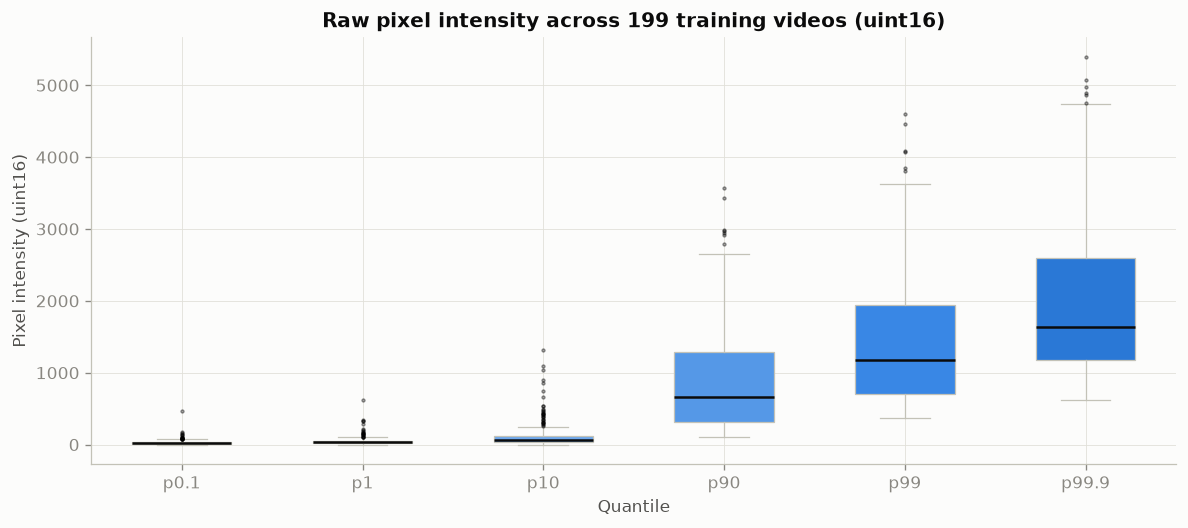

In [8]:
q_keys   = ['q0.001', 'q0.01', 'q0.1', 'q0.9', 'q0.99', 'q0.999']
q_labels = ['p0.1',   'p1',    'p10',  'p90',  'p99',   'p99.9']

fig, ax = plt.subplots(figsize=(10, 4.5))
fig.patch.set_facecolor(SURFACE)

for i, (qk, ql) in enumerate(zip(q_keys, q_labels)):
    if qk not in qdf.columns:
        continue
    vals = qdf[qk].to_numpy()
    ax.boxplot(
        vals,
        positions=[i + 1],
        widths=0.55,
        patch_artist=True,
        boxprops=dict(facecolor=SEQ[i + 2], edgecolor=BASELINE, linewidth=0.75),
        medianprops=dict(color=TEXT_PRI, linewidth=1.5),
        whiskerprops=dict(color=BASELINE, linewidth=0.75),
        capprops=dict(color=BASELINE, linewidth=0.75),
        flierprops=dict(marker='.', color=TEXT_MUTED, markersize=3, alpha=0.5),
    )

ax.set_xticks(range(1, len(q_labels) + 1))
ax.set_xticklabels(q_labels)
ax.set_title('Raw pixel intensity across 199 training videos (uint16)')
ax.set_xlabel('Quantile', color=TEXT_SEC)
ax.set_ylabel('Pixel intensity (uint16)', color=TEXT_SEC)
plt.tight_layout()
plt.show()

## 7 · Example image frame

Load a single timepoint from one training video.
The `Blues` colormap echoes the sequential ramp; intensity is clipped to [p0.1, p99.9].

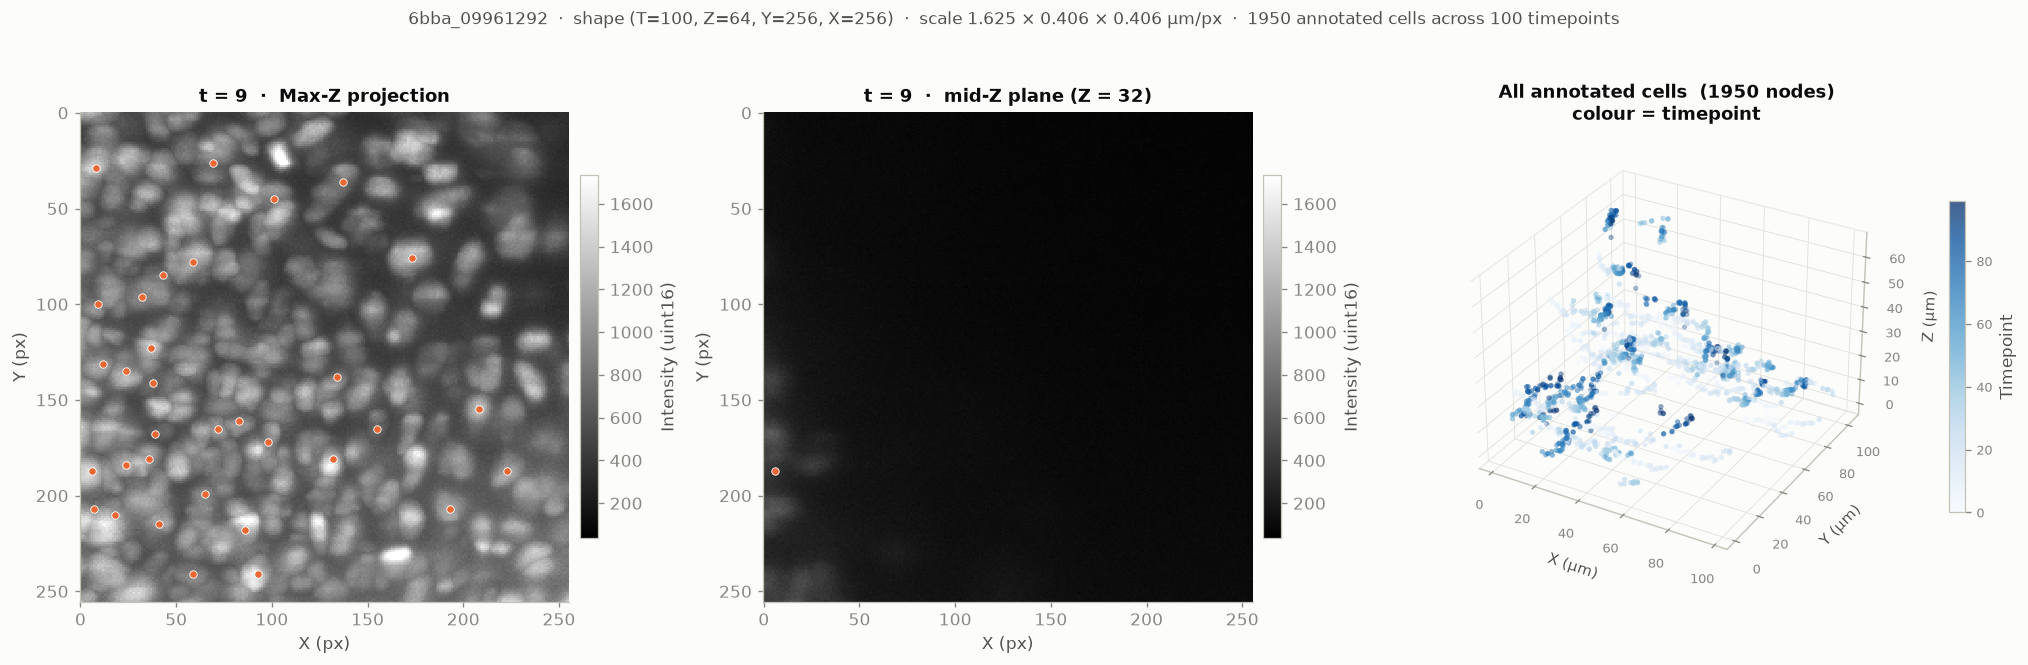

In [ ]:
sample_name = "6bba_09961292"
zg = zarr.open_group(str(TRAIN_DIR / f"{sample_name}.zarr"))
arr = zg["0"]
T, Z, Y, X = arr.shape

# Load annotated tracks
result = td.graph.IndexedRXGraph.from_geff(str(TRAIN_DIR / f"{sample_name}.geff"))
g = result[0] if isinstance(result, tuple) else result
node_df = g.node_attrs()

# Pick the frame with the most annotated cells
t_frame = int(
    node_df.group_by("t").agg(pl.len().alias("n")).sort("n", descending=True)["t"][0]
)
frame = arr[t_frame]  # (Z, Y, X)
max_proj = frame.max(axis=0)  # max-intensity Z-projection
mid_z = frame[Z // 2]  # single mid-Z plane

qs = dict(zg.attrs)["image_statistics"]["quantiles"]
vmin = float(qs["0.001"])
vmax = float(qs["0.999"])

# Physical µm coordinates for 3D scatter
SCALE_Z, SCALE_YX = 1.625, 0.40625
z_phys = node_df["z"].to_numpy() * SCALE_Z
y_phys = node_df["y"].to_numpy() * SCALE_YX
x_phys = node_df["x"].to_numpy() * SCALE_YX
t_vals = node_df["t"].to_numpy()

from mpl_toolkits.mplot3d import Axes3D  # noqa: F401

fig = plt.figure(figsize=(17, 5.5))
fig.patch.set_facecolor(SURFACE)

# ── 2-D image panels with annotated-cell overlays ───────────────────────────
frame_nodes = node_df.filter(pl.col("t") == t_frame)
near_mid_z = frame_nodes.filter(
    (pl.col("z") >= Z // 2 - 3) & (pl.col("z") <= Z // 2 + 3)
)

for col, (img, title, dots_df) in enumerate(
    [
        (max_proj, f"t = {t_frame}  ·  Max-Z projection", frame_nodes),
        (mid_z, f"t = {t_frame}  ·  mid-Z plane (Z = {Z // 2})", near_mid_z),
    ]
):
    ax = fig.add_subplot(1, 3, col + 1)
    ax.set_facecolor(SURFACE)
    im = ax.imshow(
        img, cmap="gray", vmin=vmin, vmax=vmax, interpolation="nearest", aspect="equal"
    )
    ax.set_title(title, pad=6, fontsize=11)
    ax.set_xlabel("X (px)", color=TEXT_SEC)
    ax.set_ylabel("Y (px)", color=TEXT_SEC)
    ax.tick_params(length=3, color=TEXT_MUTED)
    plt.colorbar(im, ax=ax, fraction=0.035, pad=0.02, label="Intensity (uint16)")
    ax.grid(False)
    # Orange dots (slot 2) mark annotated cell centres
    if len(dots_df) > 0:
        ax.scatter(
            dots_df["x"].to_numpy(),
            dots_df["y"].to_numpy(),
            s=20,
            c=C2,
            edgecolors="white",
            linewidths=0.5,
            zorder=5,
        )

# ── 3-D scatter: all annotated cells, colour = timepoint ────────────────────
ax3 = fig.add_subplot(1, 3, 3, projection="3d")
ax3.set_facecolor(SURFACE)

sc = ax3.scatter(
    x_phys,
    y_phys,
    z_phys,
    c=t_vals,
    cmap="Blues",
    s=10,
    alpha=0.75,
    edgecolors="none",
    vmin=t_vals.min(),
    vmax=t_vals.max(),
)
cb = plt.colorbar(sc, ax=ax3, fraction=0.03, pad=0.12)
cb.set_label("Timepoint", color=TEXT_SEC)
cb.ax.tick_params(labelsize=8)

ax3.set_xlabel("X (µm)", labelpad=4, color=TEXT_SEC, fontsize=9)
ax3.set_ylabel("Y (µm)", labelpad=4, color=TEXT_SEC, fontsize=9)
ax3.set_zlabel("Z (µm)", labelpad=4, color=TEXT_SEC, fontsize=9)
ax3.set_title(
    f"All annotated cells  ({g.num_nodes()} nodes)\ncolour = timepoint",
    pad=10,
    fontsize=11,
)
ax3.tick_params(labelsize=8)
ax3.xaxis.pane.fill = False
ax3.yaxis.pane.fill = False
ax3.zaxis.pane.fill = False
ax3.xaxis.pane.set_edgecolor(GRID)
ax3.yaxis.pane.set_edgecolor(GRID)
ax3.zaxis.pane.set_edgecolor(GRID)
ax3.grid(True, color=GRID, linewidth=0.4, alpha=0.6)

fig.suptitle(
    f"{sample_name}  ·  shape (T={T}, Z={Z}, Y={Y}, X={X})"
    f"  ·  scale 1.625 × 0.406 × 0.406 µm/px"
    f"  ·  {g.num_nodes()} annotated cells across"
    f' {int(node_df["t"].n_unique())} timepoints',
    fontsize=10,
    color=TEXT_SEC,
    y=1.01,
)
plt.tight_layout()
plt.show()

## 8 · Temporal annotation coverage

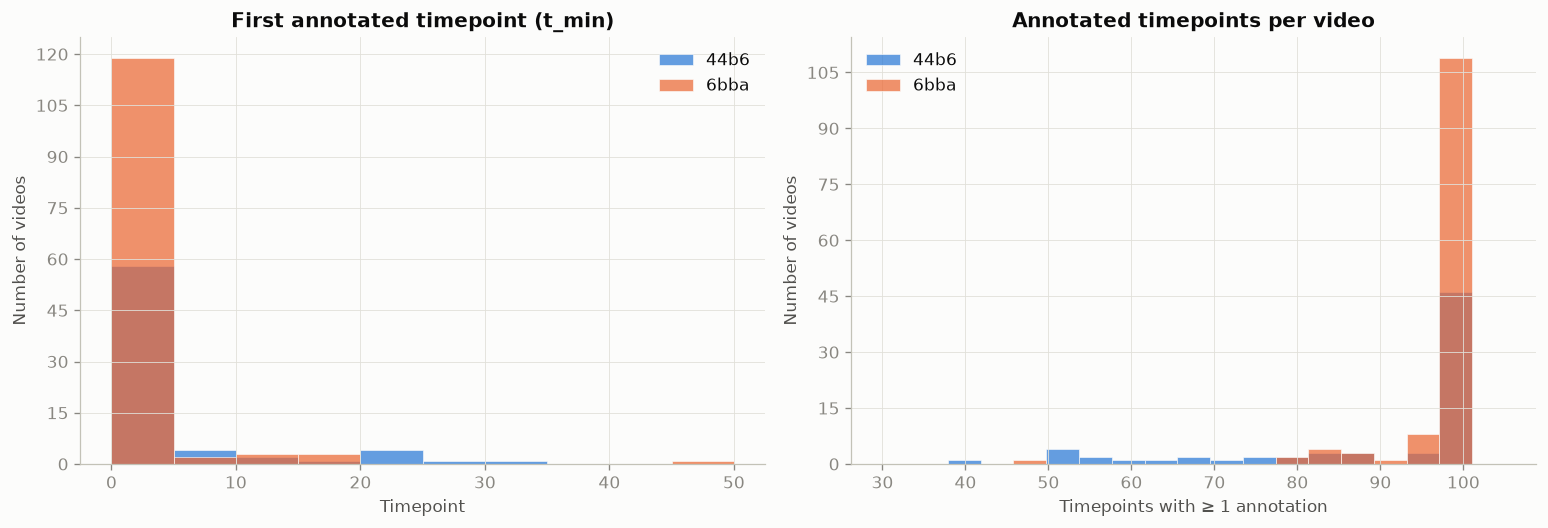

In [10]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.5))
fig.patch.set_facecolor(SURFACE)

bins_tmin   = np.arange(0, 55, 5)
bins_frames = np.linspace(30, 105, 20)

for prefix, color in prefix_colors.items():
    sub = df.filter(pl.col('prefix') == prefix)

    ax1.hist(sub['t_min'].to_numpy(), bins=bins_tmin,
             color=color, alpha=0.72, label=prefix,
             edgecolor=SURFACE, linewidth=0.5)

    ax2.hist(sub['n_frames_annotated'].to_numpy(), bins=bins_frames,
             color=color, alpha=0.72, label=prefix,
             edgecolor=SURFACE, linewidth=0.5)

for ax, title, xlabel in [
    (ax1, 'First annotated timepoint (t_min)', 'Timepoint'),
    (ax2, 'Annotated timepoints per video',    'Timepoints with ≥ 1 annotation'),
]:
    ax.set_title(title)
    ax.set_xlabel(xlabel, color=TEXT_SEC)
    ax.set_ylabel('Number of videos', color=TEXT_SEC)
    ax.yaxis.set_major_locator(MaxNLocator(integer=True))
    ax.legend(frameon=False, labelcolor=TEXT_PRI, fontsize=10)

plt.tight_layout()
plt.show()

## 9 · Cells per timepoint in sample videos

Annotation density varies across time — partly because cells enter the field of view
as the embryo develops, and partly because sparse GT skips many frames entirely.

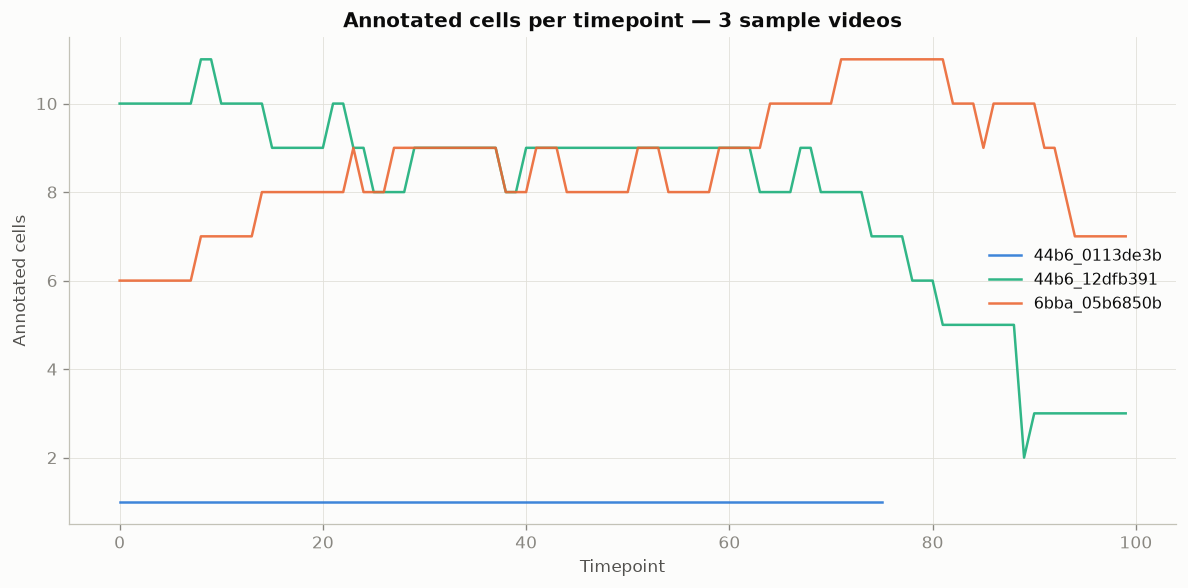

In [11]:
# Three samples: one 44b6 heavy, one 44b6 light, one 6bba
samples = [
    ('44b6_0113de3b', C1, '44b6_0113de3b'),
    ('44b6_12dfb391', C3, '44b6_12dfb391'),
    ('6bba_05b6850b', C2, '6bba_05b6850b'),
]

fig, ax = plt.subplots(figsize=(10, 5))
fig.patch.set_facecolor(SURFACE)

for name, color, label in samples:
    result  = td.graph.IndexedRXGraph.from_geff(str(TRAIN_DIR / f'{name}.geff'))
    g       = result[0] if isinstance(result, tuple) else result
    node_df = g.node_attrs()
    per_t   = node_df.group_by('t').agg(pl.len().alias('n')).sort('t')
    ax.plot(per_t['t'].to_numpy(), per_t['n'].to_numpy(),
            color=color, linewidth=1.5, alpha=0.9, label=label)

ax.set_title('Annotated cells per timepoint — 3 sample videos')
ax.set_xlabel('Timepoint', color=TEXT_SEC)
ax.set_ylabel('Annotated cells', color=TEXT_SEC)
ax.legend(frameon=False, fontsize=9.5, labelcolor=TEXT_PRI)
ax.yaxis.set_major_locator(MaxNLocator(integer=True))
plt.tight_layout()
plt.show()

## 10 · Summary statistics

In [12]:
print('=== Per-dataset statistics (train) ===')
print(df.select(['nodes','edges','divisions','n_frames_annotated','t_min','t_max']).describe())

print('\n=== By embryo series ===')
print(
    df.group_by('prefix').agg(
        pl.len().alias('videos'),
        pl.col('nodes').mean().round(0).alias('mean_nodes'),
        pl.col('edges').mean().round(0).alias('mean_edges'),
        pl.col('divisions').sum().alias('total_divisions'),
        pl.col('n_frames_annotated').mean().round(1).alias('mean_annot_frames'),
    ).sort('prefix')
)

print('\n=== Image shape & scale ===')
print(f'  Shape: T=100, Z=64, Y=256, X=256  (all videos identical)')
print(f'  Voxel scale: Z=1.625 µm, Y=0.40625 µm, X=0.40625 µm')
print(f'  Physical FOV: {64*1.625:.0f} × {256*0.40625:.0f} × {256*0.40625:.0f} µm')

=== Per-dataset statistics (train) ===
shape: (9, 7)
┌────────────┬────────────┬────────────┬───────────┬────────────────────┬──────────┬───────────┐
│ statistic  ┆ nodes      ┆ edges      ┆ divisions ┆ n_frames_annotated ┆ t_min    ┆ t_max     │
│ ---        ┆ ---        ┆ ---        ┆ ---       ┆ ---                ┆ ---      ┆ ---       │
│ str        ┆ f64        ┆ f64        ┆ f64       ┆ f64                ┆ f64      ┆ f64       │
╞════════════╪════════════╪════════════╪═══════════╪════════════════════╪══════════╪═══════════╡
│ count      ┆ 199.0      ┆ 199.0      ┆ 199.0     ┆ 199.0              ┆ 199.0    ┆ 199.0     │
│ null_count ┆ 0.0        ┆ 0.0        ┆ 0.0       ┆ 0.0                ┆ 0.0      ┆ 0.0       │
│ mean       ┆ 669.939698 ┆ 647.653266 ┆ 0.758794  ┆ 95.140704          ┆ 1.914573 ┆ 96.572864 │
│ std        ┆ 421.410482 ┆ 406.297691 ┆ 1.069367  ┆ 11.730143          ┆ 6.075929 ┆ 7.871664  │
│ min        ┆ 50.0       ┆ 49.0       ┆ 0.0       ┆ 40.0               ┆ 